# NOTEBOOK 2: KIỂM THỬ ĐỘC LẬP VÀ ĐÁNH GIÁ MÔ HÌNH (TEST & INFERENCE)
## Đề tài: Phát hiện xâm nhập mạng IoT (IoT-NIDS) trên tập dữ liệu chuẩn quốc tế IoT-23
---
### Nhiệm vụ của Notebook này:
1. **Nạp Bundle Mô hình** đã huấn luyện (`iot_nids_bundle.joblib`) từ Notebook 1.
2. **Nạp toàn bộ tập dữ liệu kiểm thử độc lập (`test_set.csv` - 1,139,259 dòng)** - dữ liệu mô hình chưa từng được thấy (Unseen Data).
3. **Đánh giá chất lượng thực tế theo chuẩn quốc tế**: Classification Report (Accuracy, Precision, Recall, F1-Score).
4. **Vẽ Ma trận nhầm lẫn (Confusion Matrix)** trên hơn 1.13 triệu dòng kiểm thử.
5. **In ra 10 dòng suy luận thực tế (Inference Demonstration)** kèm độ tin cậy của mô hình.

In [1]:
# 1. KHAI BÁO THƯ VIỆN VÀ NẠP BUNDLE MODEL ĐÃ TRAIN
import os, joblib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

bundle_path = "iot_nids_bundle.joblib"
bundle = joblib.load(bundle_path)
model = bundle["model"]
encoders = bundle["encoders"]
features = bundle["features"]
numeric_cols = bundle["numeric_cols"]
categorical_cols = bundle["categorical_cols"]

print(f"[+] Nạp thành công mô hình: {model.__class__.__name__}!")

[+] Nạp thành công mô hình: LGBMClassifier!


In [2]:
# 2. NẠP TOÀN BỘ DỮ LIỆU TẬP KIỂM THỬ ĐỘC LẬP (TEST SET - 1,139,259 DÒNG)
test_path = "test_set.csv"
print(f"[*] Đang tải dữ liệu kiểm thử độc lập từ {test_path}...")
t0 = time.time()
test_df = pd.read_csv(test_path, low_memory=False)
print(f"[+] Đã tải toàn bộ {len(test_df):,} dòng kiểm thử mới hoàn toàn (20% chuẩn quốc tế) trong {time.time()-t0:.2f}s!")
test_df.head(5)

[*] Đang tải dữ liệu kiểm thử độc lập từ c:\Study\HocKy6\IoT_NIDS_Pipeline\test_set.csv...


[+] Đã tải toàn bộ 1,139,259 dòng kiểm thử mới hoàn toàn (20% chuẩn quốc tế) trong 9.81s!


,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,...,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,tunnel_parents,label,detailed-label,scenario_tag,label_clean
0,1.532529e+09,CJZRnm3hKB6i0a4WSk,192.168.100.111,55953,147.32.35.116,23,tcp,-,-,-,...,S,1,40,0,0,(empty),Malicious,PartOfAHorizontalPortScan,Hajime,Malicious
1,1.526194e+09,Cm3FWo2LjH7N1YiFn9,192.168.100.103,43763,167.77.201.167,42492,udp,-,-,-,...,D,1,40,0,0,(empty),Benign,-,Mirai/Kenjiro,Benign
2,1.551400e+09,Cp1rD920x5rB6tIZb8,192.168.1.200,36306,193.189.81.155,23,tcp,-,0.000002,0,...,S,2,120,0,0,-,Malicious,PartOfAHorizontalPortScan,Mirai-48,Malicious
3,1.551394e+09,CqjoV31mbldov6kzug,192.168.1.200,41156,222.254.161.211,23,tcp,-,0.000001,0,...,S,2,120,0,0,-,Malicious,PartOfAHorizontalPortScan,Mirai-48,Malicious
4,1.532536e+09,CevpZN8tcvJWpETgh,192.168.100.111,3387,147.32.153.120,23,tcp,-,-,-,...,S,1,40,0,0,(empty),Malicious,PartOfAHorizontalPortScan,Hajime,Malicious


In [3]:
# 3. TIỀN XỬ LÝ VÀ CHẠY DỰ ĐOÁN SIÊU TỐC TRÊN 1.14 TRIỆU DÒNG
df_proc = test_df.copy()
for col in numeric_cols:
    df_proc[col] = pd.to_numeric(df_proc[col].replace("-", 0).replace("(empty)", 0), errors="coerce").fillna(0).astype(np.float32)

for col in categorical_cols:
    le = encoders[col]
    known_classes = dict(zip(le.classes_, le.transform(le.classes_)))
    df_proc[col] = df_proc[col].astype(str).map(known_classes).fillna(0).astype(int)

X_test = df_proc[features].values
y_test = df_proc["label_clean"].apply(lambda x: 0 if x == "Benign" else 1).values

t0 = time.time()
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)
print(f"[+] Dự đoán xong {len(X_test):,} dòng kiểm thử chỉ trong {time.time() - t0:.2f}s!\n")

print("=== BÁO CÁO PHÂN LOẠI TRÊN DỮ LIỆU TEST ĐỘC LẬP (1,139,259 DÒNG) ===")
print(classification_report(y_test, y_pred, target_names=["Benign (Sạch)", "Malicious (Độc)"], digits=4))

C:\Users\ADMIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\ADMIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[+] Dự đoán xong 1,139,259 dòng kiểm thử chỉ trong 4.89s!

=== BÁO CÁO PHÂN LOẠI TRÊN DỮ LIỆU TEST ĐỘC LẬP (1,139,259 DÒNG) ===


                 precision    recall  f1-score   support

  Benign (Sạch)     0.9998    0.9988    0.9993     99592
Malicious (Độc)     0.9999    1.0000    0.9999   1039667

       accuracy                         0.9999   1139259
      macro avg     0.9998    0.9994    0.9996   1139259
   weighted avg     0.9999    0.9999    0.9999   1139259



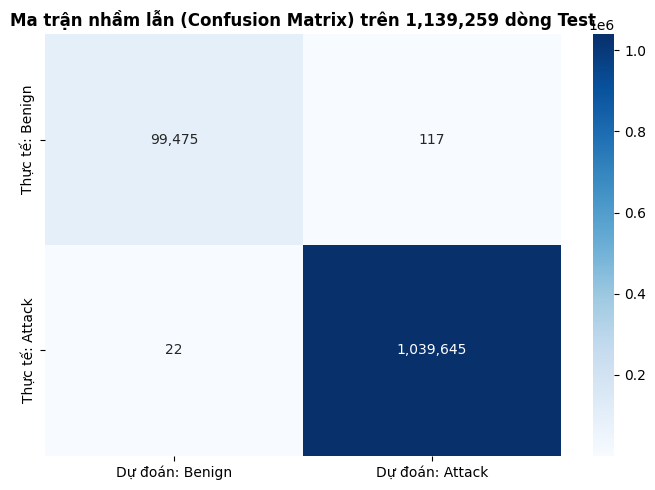

In [4]:
# 4. MA TRẬN NHẦM LẪN (CONFUSION MATRIX) TRÊN 1.14 TRIỆU DÒNG
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues",
            xticklabels=["Dự đoán: Benign", "Dự đoán: Attack"],
            yticklabels=["Thực tế: Benign", "Thực tế: Attack"])
plt.title("Ma trận nhầm lẫn (Confusion Matrix) trên 1,139,259 dòng Test", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
# 5. IN RA 10 DÒNG KẾT QUẢ SUY LUẬN THỰC TẾ
results_df = test_df.copy()
results_df["NHAN_THUC_TE"] = np.where(y_test == 0, "Benign (Sạch)", "Malicious (Độc)")
results_df["MODEL_DU_DOAN"] = np.where(y_pred == 0, "Benign (Sạch)", "Malicious (Độc)")
results_df["DO_TIN_CAY"] = [f"{np.max(p)*100:.1f}%" for p in y_proba]
results_df["KET_QUA"] = np.where(results_df["NHAN_THUC_TE"] == results_df["MODEL_DU_DOAN"], "ĐÚNG [OK]", "SAI [FAIL]")

s_benign = results_df[results_df["NHAN_THUC_TE"] == "Benign (Sạch)"].head(5)
s_mal = results_df[results_df["NHAN_THUC_TE"] == "Malicious (Độc)"].head(5)
sample_10 = pd.concat([s_benign, s_mal]).sample(frac=1, random_state=42)

cols_show = ["proto", "id.resp_p", "duration", "orig_bytes", "resp_bytes", "conn_state", "NHAN_THUC_TE", "MODEL_DU_DOAN", "DO_TIN_CAY", "KET_QUA"]
print("=== 10 DÒNG MINH HỌA MÔ HÌNH CHẠY SUY LUẬN TRÊN DỮ LIỆU TEST MỚI ===\n")
sample_10[cols_show]

=== 10 DÒNG MINH HỌA MÔ HÌNH CHẠY SUY LUẬN TRÊN DỮ LIỆU TEST MỚI ===



,proto,id.resp_p,duration,orig_bytes,resp_bytes,conn_state,NHAN_THUC_TE,MODEL_DU_DOAN,DO_TIN_CAY,KET_QUA
4,tcp,23,-,-,-,S0,Malicious (Độc),Malicious (Độc),100.0%,ĐÚNG [OK]
11,udp,62585,-,-,-,S0,Benign (Sạch),Benign (Sạch),100.0%,ĐÚNG [OK]
0,tcp,23,-,-,-,S0,Malicious (Độc),Malicious (Độc),100.0%,ĐÚNG [OK]
1,udp,42492,-,-,-,S0,Benign (Sạch),Benign (Sạch),100.0%,ĐÚNG [OK]
3,tcp,23,0.000001,0,0,S0,Malicious (Độc),Malicious (Độc),100.0%,ĐÚNG [OK]
16,udp,47959,-,-,-,S0,Benign (Sạch),Benign (Sạch),100.0%,ĐÚNG [OK]
5,tcp,23,3.151733,0,0,S0,Malicious (Độc),Malicious (Độc),100.0%,ĐÚNG [OK]
53,udp,3368,-,-,-,S0,Benign (Sạch),Benign (Sạch),100.0%,ĐÚNG [OK]
48,udp,123,0.014490,48,48,SF,Benign (Sạch),Benign (Sạch),100.0%,ĐÚNG [OK]
2,tcp,23,0.000002,0,0,S0,Malicious (Độc),Malicious (Độc),100.0%,ĐÚNG [OK]
